# 3D Dual-Sheet Visualization: Raw Feature Values (bottom) + Feature Contribution (top)

Draws two stacked diamond-shaped sheets in one 3D coordinate system, with an independent coordinate frame per sheet and horizontal latitude-oriented 3D colorbars:

- **Bottom sheet**: raw feature values from `grid_0.2deg.xlsx` (TC, VS, CPD, DTF, MOHO), bilinearly interpolated onto the fine grid of the contribution raster; light-gray frame, gray-white terrain basemap (sea = white, land = gray), data overlaid semi-transparently.

- **Top sheet**: spatial distribution of the feature contribution, one standalone PNG per feature (`combined_3d_two_sheets_{feature}.png`); frame labelled only on the Latitude axis, `coolwarm` colormap, same terrain basemap.

- **Colorbars**: both are 3D horizontal perspective bars running along Latitude (length cut by 1/3 and widened), labelled with min/max only; the bottom title is the feature abbreviation with its unit, the top title is `Contribution (mW/m²)`.

- **Coloring**: discretized with `BoundaryNorm`, 13 bins between the 2nd and 98th percentiles for both sheets; the bottom sheet uses a green-yellow-orange ramp registered as `gyo` (falls back to `RdYlGn_r`).

Input rasters come from `output\train\rbfkan\combined_rasters`.


In [9]:
# ========== Configuration and data loading ==========
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import Normalize

plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']

# Raster directory (written by train_geothermal.ipynb)
rast_dir = r'c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters'
shf_file = os.path.join(rast_dir, 'raster_a_shf.csv')

# Contribution rasters (b = 1st contribution, c = 2nd, ...)
contrib_files = sorted(glob.glob(os.path.join(rast_dir, 'raster_[b-f]_contrib_*.csv')))
for f in contrib_files:
    print(os.path.basename(f))

def load_grid(path, val_col):
    """Read a raster CSV and reshape it into a 2D grid (all-NaN rows/columns are kept so the shapes stay consistent)."""
    df = pd.read_csv(path)
    lon = np.sort(df['Lon'].unique())
    lat = np.sort(df['Lat'].unique())
    Xg, Yg = np.meshgrid(lon, lat)
    Z = df.pivot_table(index='Lat', columns='Lon', values=val_col, dropna=False).values.astype(float)
    return Xg, Yg, Z

# SHF (bottom sheet) is read once and shared by all overlays
X_shf, Y_shf, Z_shf = load_grid(shf_file, 'SHF_pred')
print(f"SHF grid: {Z_shf.shape}")

# Contribution grids of all features (each overlay is drawn separately)
contrib_grids = {}
for _f in contrib_files:
    _feat = os.path.basename(_f).split('_contrib_')[1].replace('.csv', '')
    contrib_grids[_feat] = load_grid(_f, 'Contribution')

# The 1st contribution feature is the top-sheet default; change TOP_INDEX to switch
TOP_INDEX = 0
top_feat = os.path.basename(contrib_files[TOP_INDEX]).split('_contrib_')[1].replace('.csv', '')
X_con, Y_con, Z_con = contrib_grids[top_feat]
print(f"Current demo feature: {top_feat} | Loaded contributions: {list(contrib_grids.keys())}")
# ========== Raw feature values (grid_0.2deg.xlsx), bilinearly interpolated onto the contribution grid (bottom sheet) ==========
from scipy.interpolate import RegularGridInterpolator

# Contribution feature -> raw column in grid_0.2deg.xlsx
FEATURE_COL_MAP = {
    'TC':   'Thermal Conductivity （mW/K/m/）',
    'VS':   'vs8',
    'CPD':  'cpd',
    'DTF':  'DTF',
    'MOHO': 'H(km)',
}
# Bottom-sheet legends: feature -> (colorbar title, colormap)
# The green -> yellow -> orange ramp reuses ColorBrewer anchors from RdYlGn and YlOrRd,
# so it stays subdued and clearly distinct from the coolwarm top sheet.
# Registered as 'gyo' so the rest of the code can keep using plt.get_cmap(...).
try:
    from matplotlib.colors import LinearSegmentedColormap as _LSC
    _gyo = _LSC.from_list('gyo', ['#1a9850', '#a6d96a', '#ffffbf', '#fdae61', '#f46d43'])
    try:
        from matplotlib import colormaps as _mplcmaps      # matplotlib >= 3.5
        _mplcmaps.register(_gyo, name='gyo', force=True)
    except Exception:
        plt.register_cmap(cmap=_gyo)                        # older matplotlib
    BOTTOM_CMAP = 'gyo'
except Exception as _e:
    print(f'could not build the custom gyo ramp ({_e}) -> falling back to RdYlGn_r')
    BOTTOM_CMAP = 'RdYlGn_r'

BOTTOM_LABELS = {
    'TC':   ('TC (mW/K/m)', BOTTOM_CMAP),
    'VS':   ('VS (km/s)', BOTTOM_CMAP),
    'CPD':  ('CPD (km)', BOTTOM_CMAP),
    'DTF':  ('DTF (°)', BOTTOM_CMAP),
    'MOHO': ('MOHO (km)', BOTTOM_CMAP),
}

_orig_file = r'c:\KAN-OLS-SHF\output\grid_0.2deg.xlsx'
_odf = pd.read_excel(_orig_file)
_lon_g = np.sort(_odf['Longitude'].unique())
_lat_g = np.sort(_odf['Latitude'].unique())
print(f"grid_0.2deg raw grid: {len(_lon_g)} lon x {len(_lat_g)} lat")
print(f"Bottom-sheet colormap: {BOTTOM_CMAP}")

def bilinear_to_fine(lon_g, lat_g, z, Xf, Yf):
    """Bilinearly interpolate a 0.2-deg coarse grid z onto the fine grid (Xf, Yf)."""
    v = np.asarray(z, dtype=float).reshape(len(lat_g), len(lon_g))
    _rgi = RegularGridInterpolator((lon_g, lat_g), v.T, method='linear',
                                   bounds_error=False, fill_value=np.nan)
    return _rgi(np.column_stack([Xf.ravel(), Yf.ravel()])).reshape(Xf.shape)

# Build a raw-value raster (fine grid, same mask as the contribution) for each feature
orig_grids = {}
for _feat, (_Xc, _Yc, _Zc) in contrib_grids.items():
    _col = FEATURE_COL_MAP[_feat]
    _z = _odf.pivot_table(index='Latitude', columns='Longitude', values=_col, dropna=False).values.astype(float)
    _Zo = bilinear_to_fine(_lon_g, _lat_g, _z, _Xc, _Yc)
    _Zo[~np.isfinite(_Zc)] = np.nan   # apply the same study-area mask as the contribution
    orig_grids[_feat] = (_Xc, _Yc, _Zo)
    print(f"[{_feat}] {_col}: valid after interpolation {np.isfinite(_Zo).sum()}/{_Zo.size}")


raster_b_contrib_TC.csv
raster_c_contrib_VS.csv
raster_d_contrib_CPD.csv
raster_e_contrib_DTF.csv
raster_f_contrib_MOHO.csv
SHF grid: (2001, 1925)
Current demo feature: TC | Loaded contributions: ['TC', 'VS', 'CPD', 'DTF', 'MOHO']
grid_0.2deg raw grid: 51 lon x 81 lat
Bottom-sheet colormap: gyo
[TC] Thermal Conductivity （mW/K/m/）: valid after interpolation 1918192/3851925
[VS] vs8: valid after interpolation 1918192/3851925
[CPD] cpd: valid after interpolation 1918192/3851925
[DTF] DTF: valid after interpolation 1918192/3851925
[MOHO] H(km): valid after interpolation 1918192/3851925


[GMT] No local proxy detected, will try a direct connection to the GMT data server
Gray-white terrain basemap: (789, 559)


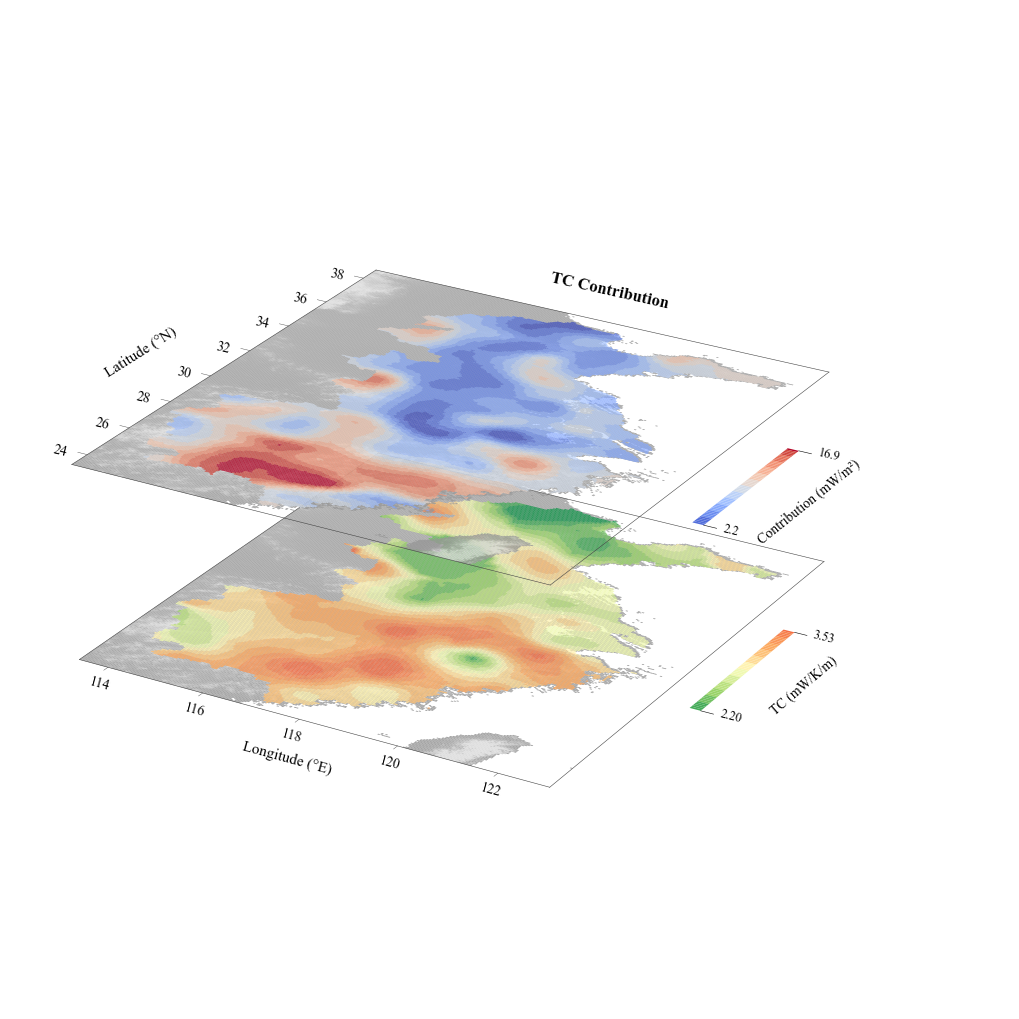

c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\PIL\Image.py:3578: DecompressionBombWarning: Image size (100000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


📐 [TC] white margins cropped: 10000x10000 -> 8141x5342
💾 [TC] saved: c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters\combined_3d_two_sheets_TC.png


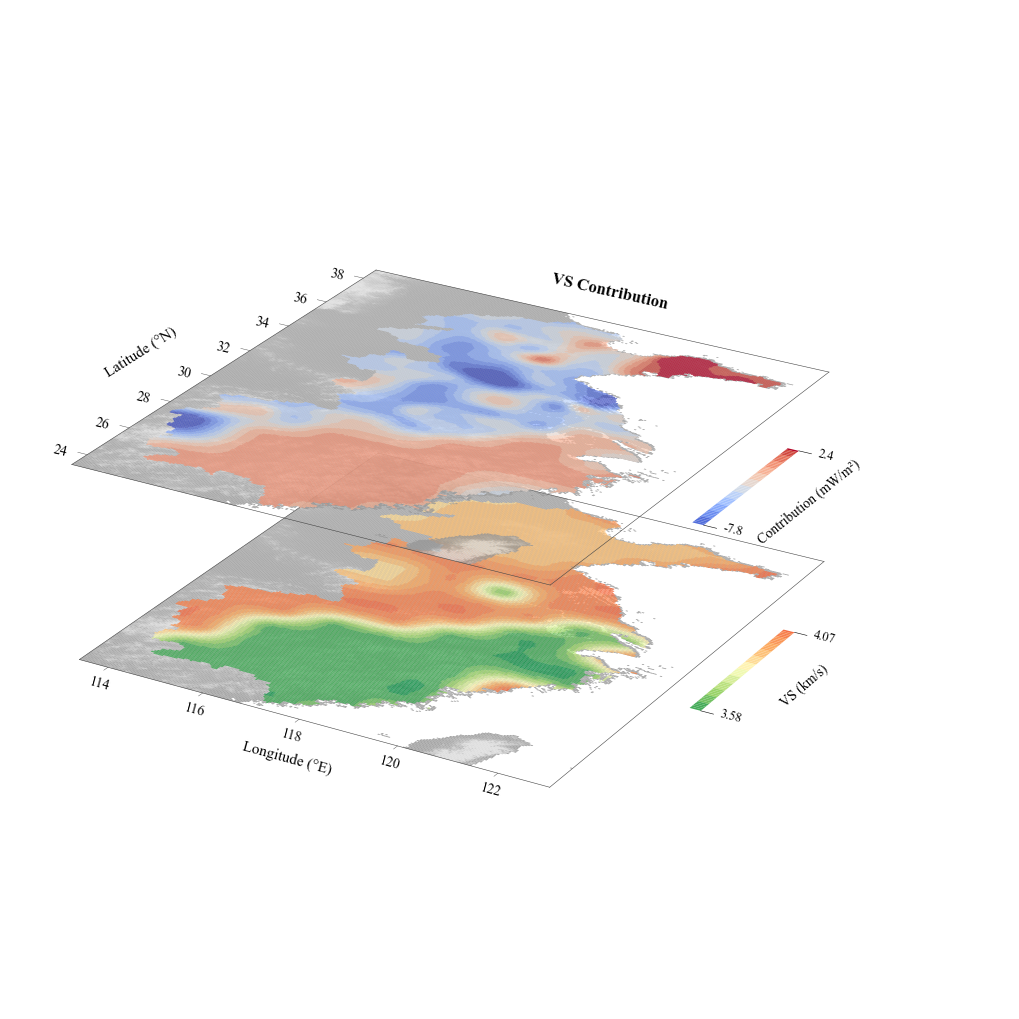

📐 [VS] white margins cropped: 10000x10000 -> 8141x5342
💾 [VS] saved: c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters\combined_3d_two_sheets_VS.png


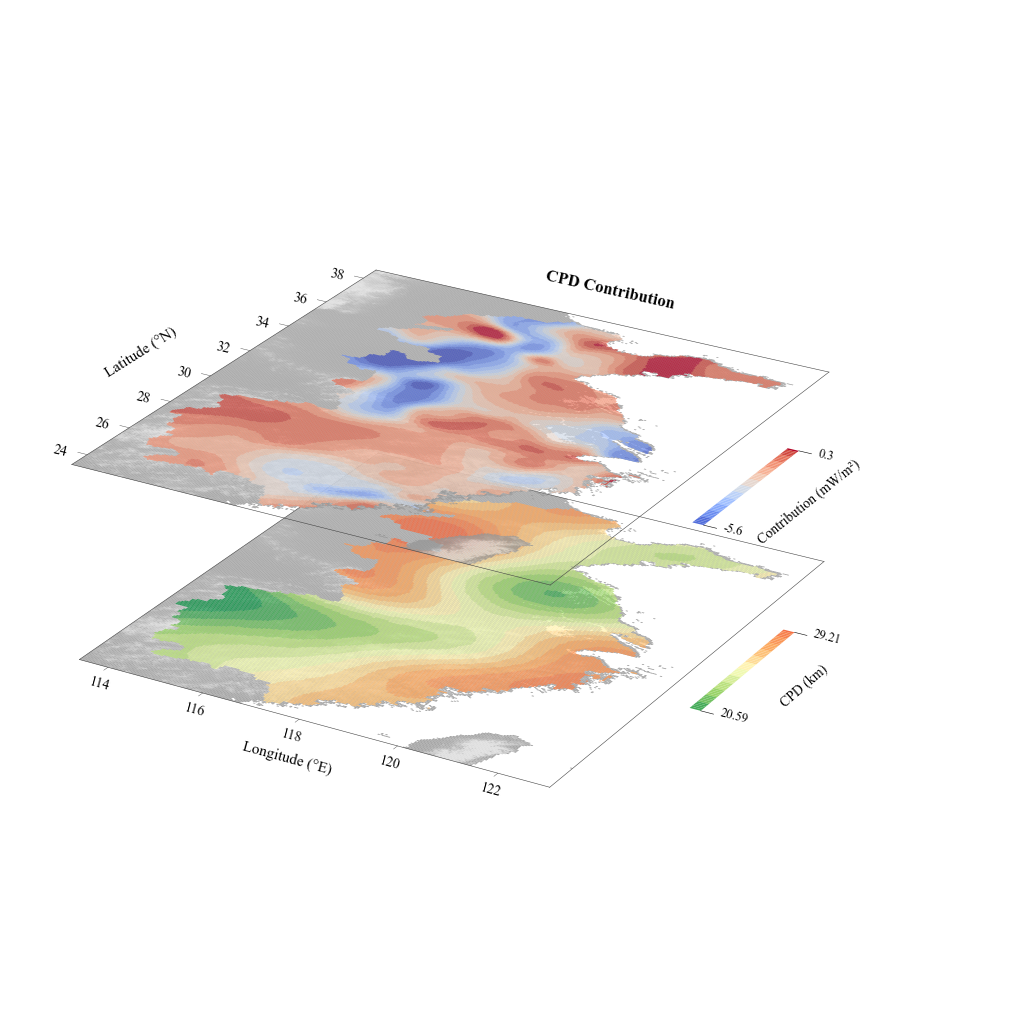

📐 [CPD] white margins cropped: 10000x10000 -> 8141x5342
💾 [CPD] saved: c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters\combined_3d_two_sheets_CPD.png


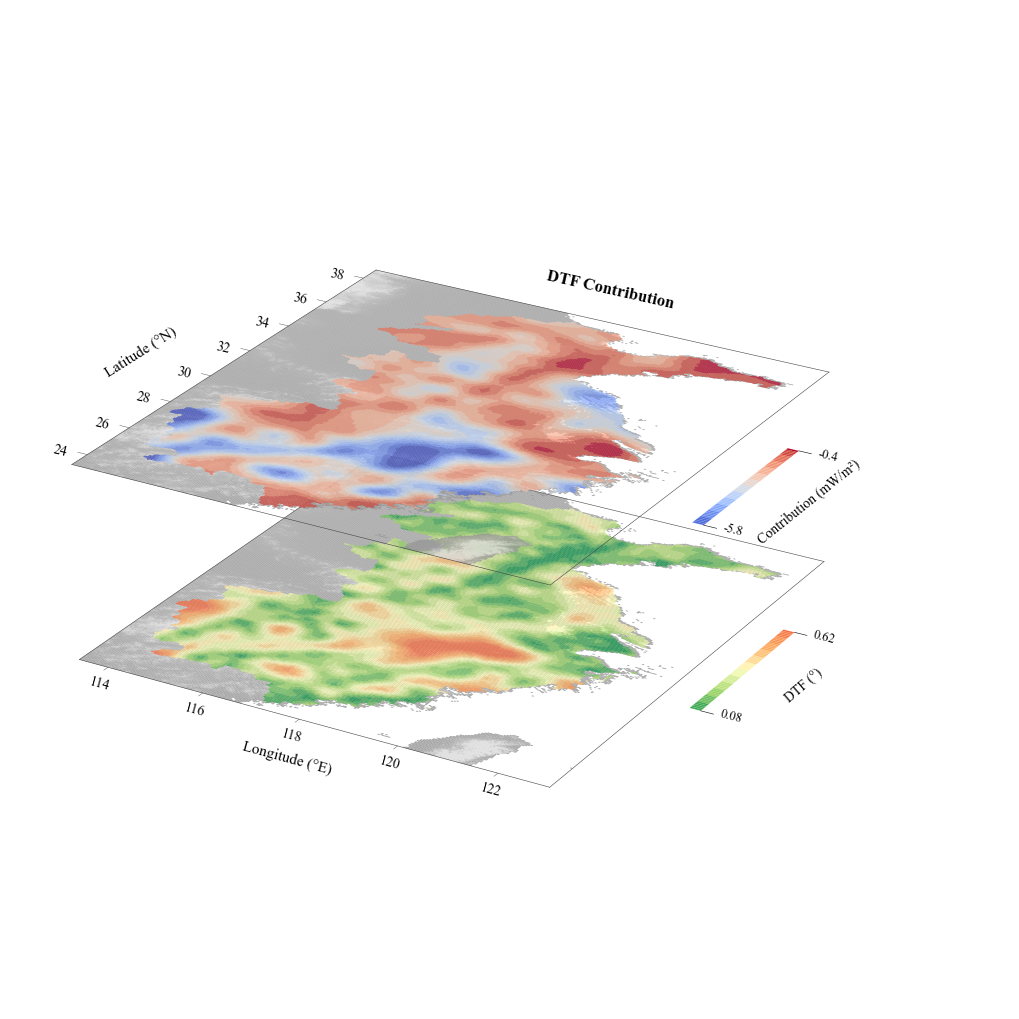

📐 [DTF] white margins cropped: 10000x10000 -> 8141x5342
💾 [DTF] saved: c:\KAN-OLS-SHF\output\train\rbfkan\combined_rasters\combined_3d_two_sheets_DTF.png


In [10]:
# ========== 3D dual sheet: draw the TC, VS, CPD and DTF overlays one at a time (feature on top, SHF below) ==========
import numpy as np
from matplotlib.colors import BoundaryNorm
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ==================== Gray-white terrain basemap (sea = white, land = gray) ====================
import matplotlib.colors as _mcolors

class GrayTerrainNorm(_mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # below sea level: pure white
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_gray_norm = GrayTerrainNorm()
import socket as _socket
_proxy_host, _proxy_port = '127.0.0.1', 7890
_sock = _socket.socket(_socket.AF_INET, _socket.SOCK_STREAM)
_sock.settimeout(0.3)
try:
    _sock.connect((_proxy_host, _proxy_port))
    _proxy_ok = True
except OSError:
    _proxy_ok = False
finally:
    _sock.close()
if _proxy_ok:
    _proxy_url = f'http://{_proxy_host}:{_proxy_port}'
    for _key in ('http_proxy', 'https_proxy', 'HTTP_PROXY', 'HTTPS_PROXY', 'GMT_HTTP_PROXY'):
        os.environ[_key] = _proxy_url
else:
    print('[GMT] No local proxy detected, will try a direct connection to the GMT data server')
_terr_cache = {'lon': None, 'lat': None, 'dem': None, 'key': None}

def load_gray_terrain(xmin, xmax, ymin, ymax):
    # Load/cache the gray-white terrain basemap; loaded once per region
    _key = (round(xmin, 3), round(xmax, 3), round(ymin, 3), round(ymax, 3))
    if _terr_cache['key'] == _key and _terr_cache['dem'] is not None:
        return _terr_cache['lon'], _terr_cache['lat'], _terr_cache['dem']
    try:
        import os as _os
        _env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
        _os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
        _os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                               _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                               _os.environ.get('PATH', ''))
        _tmpdir = r'C:\Users\19023\AppData\Local\Temp'
        _os.makedirs(_tmpdir, exist_ok=True)
        for _k in ('TMPDIR', 'TEMP', 'TMP'):
            _os.environ[_k] = _tmpdir
        import pygmt
        _relief = pygmt.datasets.load_earth_relief(
            resolution='15s', region=[xmin - 1.0, xmax + 1.0, ymin - 0.5, ymax + 0.5], registration=None)
        _step = 5
        _lon, _lat = np.meshgrid(_relief.lon.values[::_step], _relief.lat.values[::_step])
        _dem = _relief.values[::_step, ::_step].astype(float)
        _terr_cache['lon'], _terr_cache['lat'], _terr_cache['dem'], _terr_cache['key'] = _lon, _lat, _dem, _key
        print('Gray-white terrain basemap: %s' % (str(_dem.shape),))
        return _lon, _lat, _dem
    except Exception as _e:
        print('Terrain loading failed, skipping the terrain basemap: %s' % _e)
        return None, None, None

def plot_terrain_sheet(ax, height, zorder, xmin, xmax, ymin, ymax, target=280):
    # Draw the gray-white terrain sheet at the given height, limited to the study extent
    _lon, _lat, _dem = load_gray_terrain(xmin, xmax, ymin, ymax)
    if _dem is None:
        return None
    _step = max(1, int(round(_dem.shape[1] / float(target))))
    Xs, Ys = _lon[::_step, ::_step], _lat[::_step, ::_step]
    Ds = _dem[::_step, ::_step].copy()
    Ds[(Xs < xmin) | (Xs > xmax) | (Ys < ymin) | (Ys > ymax)] = np.nan
    ny, nx = Xs.shape
    Ms = ~np.isfinite(Ds)
    fvalid = ~(Ms[:-1, :-1] | Ms[:-1, 1:] | Ms[1:, :-1] | Ms[1:, 1:])
    i, j = np.nonzero(fvalid)
    if len(i) == 0:
        return None
    h = float(height)
    pts = np.empty((len(i), 4, 3), dtype=float)
    pts[:, 0, 0] = Xs[i, j];     pts[:, 0, 1] = Ys[i, j];     pts[:, 0, 2] = h
    pts[:, 1, 0] = Xs[i, j + 1]; pts[:, 1, 1] = Ys[i, j + 1]; pts[:, 1, 2] = h
    pts[:, 2, 0] = Xs[i + 1, j + 1]; pts[:, 2, 1] = Ys[i + 1, j + 1]; pts[:, 2, 2] = h
    pts[:, 3, 0] = Xs[i + 1, j]; pts[:, 3, 1] = Ys[i + 1, j]; pts[:, 3, 2] = h
    cols = plt.cm.Greys_r(_gray_norm(Ds[i, j])).copy()
    cols[Ds[i, j] <= 0.0, :3] = 1.0   # below sea level: pure white
    pc = Poly3DCollection(list(pts), facecolors=list(cols), edgecolors='none', shade=False, alpha=None)
    pc.set_zorder(zorder)
    ax.add_collection3d(pc)
    return pc


def pct_range(Z, p=(2, 98)):
    v = Z[np.isfinite(Z)]
    if v.size == 0:
        return 0.0, 1.0
    lo, hi = np.percentile(v, p)
    if hi - lo < 1e-12:
        lo, hi = lo - 1, hi + 1
    return lo, hi

def lighten(c, f):
    """Blend an RGBA color toward white by a fraction f (array-safe)."""
    c = np.asarray(c, dtype=float)
    if f <= 0:
        return c
    c = c.copy()
    if c.ndim == 1:
        c[:3] = c[:3] + (1.0 - c[:3]) * f
    else:
        c[..., :3] = c[..., :3] + (1.0 - c[..., :3]) * f
    return c

from mpl_toolkits.mplot3d import proj3d

def _edge_angle(ax, x, y, z, d):
    """Screen-space projection angle (degrees) of the 3D direction d at point (x, y, z)."""
    p = proj3d.proj_transform(x, y, z, ax.get_proj())
    p2 = proj3d.proj_transform(x + d[0], y + d[1], z + d[2], ax.get_proj())
    dx, dy = p2[0] - p[0], p2[1] - p[1]
    a = np.degrees(np.arctan2(dy, dx))
    a = (a + 180) % 180 - 180
    if a <= -90:
        a += 180
    return a


def _persp_text(ax, x, y, z, s, d=(1, 0, 0), **kw):
    """Place 2D text at the 3D point (x, y, z) with its baseline along the screen projection of direction d,
    so it is perspective-aligned with the sheet edge."""
    a = _edge_angle(ax, x, y, z, d)
    px, py, _ = proj3d.proj_transform(x, y, z, ax.get_proj())
    disp = ax.transData.transform((px, py))
    fig = ax.figure
    _w, _h = fig.get_size_inches()
    _dpi = fig.dpi
    return fig.text(disp[0] / (_w * _dpi), disp[1] / (_h * _dpi), s, rotation=a, **kw)
STEP_BOTTOM, STEP_TOP = 8, 6   # sampling step (finer on the top sheet to avoid thick blocks)
Z_OFF = 0.30                   # vertical offset between the two sheets
LIGHTEN_TOP = 0.0              # top-sheet brightening ratio (0 = no brightening)

def plot_sheet(ax, Xg, Yg, Zval, height, cmap, norm, STEP, zorder, lf=0.0, alpha=1.0):
    """Per-face Poly3DCollection: each quad gets one flat color, avoiding per-vertex shading artifacts.
    lf: brightening ratio passed to lighten()."""
    mask = ~np.isfinite(Zval)
    Xs, Ys = Xg[::STEP, ::STEP], Yg[::STEP, ::STEP]
    Ms = mask[::STEP, ::STEP]
    Zs = Zval[::STEP, ::STEP]
    ny, nx = Xs.shape
    fvalid = ~(Ms[:-1, :-1] | Ms[:-1, 1:] | Ms[1:, :-1] | Ms[1:, 1:])
    i, j = np.nonzero(fvalid)
    h = float(height)
    pts = np.empty((len(i), 4, 3), dtype=float)
    pts[:, 0, 0] = Xs[i, j];     pts[:, 0, 1] = Ys[i, j];     pts[:, 0, 2] = h
    pts[:, 1, 0] = Xs[i, j + 1]; pts[:, 1, 1] = Ys[i, j + 1]; pts[:, 1, 2] = h
    pts[:, 2, 0] = Xs[i + 1, j + 1]; pts[:, 2, 1] = Ys[i + 1, j + 1]; pts[:, 2, 2] = h
    pts[:, 3, 0] = Xs[i + 1, j]; pts[:, 3, 1] = Ys[i + 1, j]; pts[:, 3, 2] = h
    cols = lighten(cmap(norm(Zs[i, j])), lf)
    pc = Poly3DCollection(list(pts), facecolors=list(cols), edgecolors='none', shade=False, alpha=alpha)
    pc.set_zorder(zorder)
    ax.add_collection3d(pc)
    return pc

def draw_frame(ax, Xg, Yg, height, zorder, tick_lon=2.0, tick_lat=2.0, fs=10,
               name_lon='Longitude (°E)', name_lat='Latitude (°N)', label=None,
               label_x=None, label_y=None, label_ha='right', fc='#444444',
               tc='k', lw_b=0.4, lw_t=0.3, ticks_lon=True, ticks_lat=True):
    """Draw an independent coordinate frame along the four edges of the sheet:
    thin dark-gray border, lon/lat ticks, axis names and a panel label."""
    lon0, lon1 = float(Xg.min()), float(Xg.max())
    lat0, lat1 = float(Yg.min()), float(Yg.max())
    tl = 0.2  # tick length in degrees
    for (xa, ya, xb, yb) in [(lon0, lat0, lon1, lat0), (lon0, lat1, lon1, lat1),
                             (lon0, lat0, lon0, lat1), (lon1, lat0, lon1, lat1)]:
        ax.plot3D([xa, xb], [ya, yb], [height, height], color=fc, lw=lw_b, zorder=zorder)
    if ticks_lon:
        for lon in np.arange(np.ceil(lon0), lon1 + 1e-9, tick_lon):
            ax.plot3D([lon, lon], [lat0, lat0 - tl], [height, height], color=fc, lw=lw_t, zorder=zorder)
            _persp_text(ax, lon, lat0 - tl - 0.2, height, f'{lon:.0f}', d=(1, 0, 0), fontsize=fs, color=tc, ha='center', va='top')
    if ticks_lat:
        for lat in np.arange(np.ceil(lat0), lat1 + 1e-9, tick_lat):
            ax.plot3D([lon0, lon0 - tl], [lat, lat], [height, height], color=fc, lw=lw_t, zorder=zorder)
            _persp_text(ax, lon0 - tl - 0.2, lat, height, f'{lat:.0f}', d=(1, 0, 0), fontsize=fs, color=tc, ha='right', va='center')
    if name_lon:
        _persp_text(ax, (lon0 + lon1) / 2, lat0 - tl - 0.9, height, name_lon, d=(1, 0, 0), fontsize=fs + 1, color=tc, ha='center', va='top')
    if name_lat:
        _persp_text(ax, lon0 - tl - 0.9, (lat0 + lat1) / 2, height, name_lat, d=(0, 1, 0), fontsize=fs + 1, color=tc, ha='right', va='center')
    if label:
        lx = lon1 - 0.2 if label_x is None else label_x
        ly = lat1 + 0.3 if label_y is None else label_y
        _persp_text(ax, lx, ly, height, label, d=(1, 0, 0), fontsize=fs + 2, color=tc, ha=label_ha, va='bottom', fontweight='bold')

def add_3d_colorbar(ax, c_lon, y0, y1, height, cmap, norm, levels,
                    label='', fs=10, width=0.22, tick_len=0.25,
                    tick_fmt='{:.0f}', show=None, zorder=6, lf=0.0):
    """Draw a horizontal colorbar running along Latitude inside the 3D space: bar, ticks and label.
    lf: brightening ratio."""
    n = 60
    ys = np.linspace(y0, y1, n + 1)
    x0, x1 = c_lon - width / 2, c_lon + width / 2
    vals = np.linspace(norm.vmin, norm.vmax, n)
    verts, cols = [], []
    for j in range(n):
        verts.append([(x0, ys[j], height), (x1, ys[j], height),
                      (x1, ys[j + 1], height), (x0, ys[j + 1], height)])
        cols.append(lighten(np.array(cmap(norm(vals[j]))), lf))
    pc = Poly3DCollection(verts, facecolors=cols, edgecolors='none', shade=False, alpha=1.0)
    pc.set_zorder(zorder)
    ax.add_collection3d(pc)
    if show is None:
        show = levels
    for v in show:
        t = (v - norm.vmin) / (norm.vmax - norm.vmin)
        yv = y0 + t * (y1 - y0)
        ax.plot3D([x1, x1 + tick_len], [yv, yv], [height, height], color='k', lw=0.4, zorder=zorder + 1)
        _persp_text(ax, x1 + tick_len + 0.10, yv, height, tick_fmt.format(v), d=(1, 0, 0), fontsize=fs, color='k', ha='left', va='center')
    # Title to the right of the colorbar, at mid-height
    _persp_text(ax, x1 + tick_len + 0.85, (y0 + y1) / 2, height, label, d=(0, 1, 0), fontsize=fs + 1, color='k', ha='center', va='center')

# ---- Draw TC, VS, CPD and DTF separately (indices 0/1/2/3) ----
FEATURE_INDICES = [0, 1, 2, 3]

for _ti in FEATURE_INDICES:
    _feat = os.path.basename(contrib_files[_ti]).split('_contrib_')[1].replace('.csv', '')
    _Xc, _Yc, _Zc = contrib_grids[_feat]

    # Discretized coloring for this feature (13 bins between the 2nd/98th percentiles)
    lo_c, hi_c = pct_range(_Zc)
    levels_c = np.linspace(lo_c, hi_c, 13)
    norm_c = BoundaryNorm(levels_c, ncolors=256, extend='both')
    cmap_c = plt.cm.coolwarm

    # Bottom sheet: raw values of this feature on the contribution grid, with its own discretized coloring
    _Xo, _Yo, _Zo = orig_grids[_feat]
    lo_b, hi_b = pct_range(_Zo)
    levels_b = np.linspace(lo_b, hi_b, 13)
    norm_b = BoundaryNorm(levels_b, ncolors=256, extend='both')
    cmap_b = plt.get_cmap(BOTTOM_LABELS[_feat][1])
    _bot_label = BOTTOM_LABELS[_feat][0]

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111, projection='3d', position=[0.0, 0.0, 1.0, 1.0])
    try:
        ax.computed_zorder = False   # sort by explicit zorder to avoid spatial misalignment
    except AttributeError:
        pass

    lon0, lon1 = float(X_shf.min()), float(X_shf.max())
    lat0, lat1 = float(Y_shf.min()), float(Y_shf.max())
    lat_mid = (lat0 + lat1) / 2

    # No background axes, diamond view angle, explicit limits
    ax.set_axis_off()
    ax.view_init(elev=25, azim=-60)
    ax.set_box_aspect((1.2, 1.0, 0.5))
    ax.set_xlim(lon0 - 0.6, lon1 + 3.2)
    ax.set_ylim(lat0 - 0.6, lat1 + 0.9)
    ax.set_zlim(-0.02, 0.42)

    # Draw order (zorder): bottom terrain (1) -> bottom sheet (2) -> bottom frame (3)
    #                      -> top terrain (4) -> top sheet (5) -> top frame (6) -> colorbars (8)
    # Terrain and data share one plane: the opaque terrain is drawn first, then the data is
    # overlaid semi-transparently (alpha=0.9), matching the 2D raster style
    plot_terrain_sheet(ax, 0.0, 1, lon0, lon1, lat0, lat1)
    plot_sheet(ax, _Xo, _Yo, _Zo, 0.0, cmap_b, norm_b, STEP_BOTTOM, zorder=2, alpha=0.9)
    draw_frame(ax, _Xo, _Yo, 0.0, zorder=3, name_lat='', label=None, ticks_lat=False)
    plot_terrain_sheet(ax, Z_OFF, 4, lon0, lon1, lat0, lat1)
    plot_sheet(ax, _Xc, _Yc, _Zc, Z_OFF, cmap_c, norm_c, STEP_TOP, zorder=5, lf=LIGHTEN_TOP, alpha=0.9)
    draw_frame(ax, _Xc, _Yc, Z_OFF, zorder=6, name_lon='', ticks_lon=False,
               label=f'{_feat} Contribution',
               label_x=lon0 + 0.50 * (lon1 - lon0), label_y=lat1 + 0.7, label_ha='center')

    # Two horizontal 3D perspective colorbars along Latitude, with the titles on the right
    cb_half = 4.0 * 2 / 3
    cb_y0, cb_y1 = lat_mid - cb_half, lat_mid + cb_half
    add_3d_colorbar(ax, lon1 + 1.0, cb_y0, cb_y1, 0.02, cmap_b, norm_b, levels_b,
                    label=_bot_label, fs=9, show=[levels_b[0], levels_b[-1]], tick_fmt='{:.2f}', zorder=8)
    add_3d_colorbar(ax, lon1 + 1.0, cb_y0, cb_y1, Z_OFF, cmap_c, norm_c, levels_c,
                    label='Contribution (mW/m²)', fs=9,
                    show=[levels_c[0], levels_c[-1]], tick_fmt='{:.1f}', lf=LIGHTEN_TOP, zorder=8)


    out_png = os.path.join(rast_dir, f'combined_3d_two_sheets_{_feat}.png')
    plt.savefig(out_png, dpi=1000)
    plt.show()

    # Crop the surrounding white margin to the content bounding box
    from PIL import Image as _Im
    _im = _Im.open(out_png)
    _arr = np.asarray(_im.convert('RGB'))
    _fg = ~((_arr[..., 0] >= 250) & (_arr[..., 1] >= 250) & (_arr[..., 2] >= 250))
    _r = np.where(_fg.any(axis=1))[0]
    _c = np.where(_fg.any(axis=0))[0]
    _pad = 40
    _r0 = max(int(_r[0]) - _pad, 0); _r1 = min(int(_r[-1]) + _pad, _arr.shape[0])
    _c0 = max(int(_c[0]) - _pad, 0); _c1 = min(int(_c[-1]) + _pad, _arr.shape[1])
    _im.crop((_c0, _r0, _c1, _r1)).save(out_png)
    print(f"📐 [{_feat}] white margins cropped: {_arr.shape[1]}x{_arr.shape[0]} -> {_c1-_c0}x{_r1-_r0}")
    print(f"💾 [{_feat}] saved: {out_png}")
